# Spec 3 — Detector noise floor

Mode-sorting (MS) Fisher information and Cramér–Rao bounds under a θ-independent additive count floor `β = b_j / τ` in each channel (dark counts + background light), swept over `BETA_INTERVAL` from `simulate_bounds.py` at fixed photon budget `τ`.

**Encoding** (same as the other example notebooks): each curve *family* (colormap hue) is one background level `β`, decoded by the legend; the light→dark gradient within a family is the *other* geometric parameter, decoded by the shared colorbar.

**Headline:** the floor sits in the FI denominator `τ P_j + b_j`, so it hurts low-probability channels first. The mode that carries the most depth information, `(0,2)`, is also the *faintest* channel, so depth degrades before width as `β` grows.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from simulate_bounds import BETA_INTERVAL, IMPORTANT_MODES

from visualize_helpers import (
    draw_fi_curves,
    fi_legend_handles_labeled,
    latexify,
    plot_fi_comparison_labeled,
)

latexify()
FORMAT = "pdf"

# One colormap family per background level. Family/hue encodes beta (legend);
# light->dark within a family encodes the gradient parameter (colorbar).
continuous_cmaps = [
    "Blues",
    "Greens",
    "Reds",
    "Purples",
    "Oranges",
    "plasma",
    "magma",
    "pink",
    "viridis",
    "cividis",
]

In [2]:
%matplotlib inline

In [3]:
# Background levels to plot (defaults to the full swept set; trim for clarity).
SELECTED_BETAS = BETA_INTERVAL[::2]

# FI channel layout: one channel per measurement mode in IMPORTANT_MODES order,
# plus a final remainder ("bucket") channel.
DEPTH_MODE_CHANNELS = [
    IMPORTANT_MODES.index((2, 0)),
    IMPORTANT_MODES.index((0, 2)),
]  # faint second-order modes carrying the depth signal

# Parameter index inside the 2x2 FI block: 0 = delta x (width), 1 = delta z (depth).
DX, DZ = 0, 1


def beta_filename(beta):  # noqa: ANN001, ANN201
    """Filename stem written by simulate_bounds (matches f'{i:.0e}')."""
    return f"{beta:.0e}"


def beta_legend(beta):  # noqa: ANN001, ANN201
    """Math-text legend label for a background level beta."""
    if beta == 0:
        return r"$\beta=0$"
    exp = int(np.floor(np.log10(beta) + 1e-9))
    mant = round(beta / 10**exp)
    if mant == 1:
        return rf"$\beta=10^{{{exp}}}$"
    return rf"$\beta={mant}\times10^{{{exp}}}$"


coords = np.load("coordinates.npy")
x_range = coords[:, 0, 2]  # transverse separation delta x  (array axis 0)
p_range = -coords[0, :, 6]  # axial displacement   delta z  (array axis 1)

labels = [beta_legend(b) for b in SELECTED_BETAS]
cmaps = continuous_cmaps[: len(SELECTED_BETAS)]

fis = []  # FI matrices, shape (Nx, Nz, n_modes + 1, 2, 2)
fis_inv = []  # CRB (inverse of channel-summed FI), shape (Nx, Nz, 2, 2)
for beta in SELECTED_BETAS:
    stem = beta_filename(beta)
    fis.append(np.load(f"fi_ms_{stem}.npy"))
    fis_inv.append(np.load(f"fi_ms_inv_{stem}_with_remainder.npy"))

[fi.shape for fi in fis]

[(50, 50, 5, 2, 2), (50, 50, 5, 2, 2), (50, 50, 5, 2, 2), (50, 50, 5, 2, 2)]

## Width — Fisher information $H_{\delta x \delta x}$

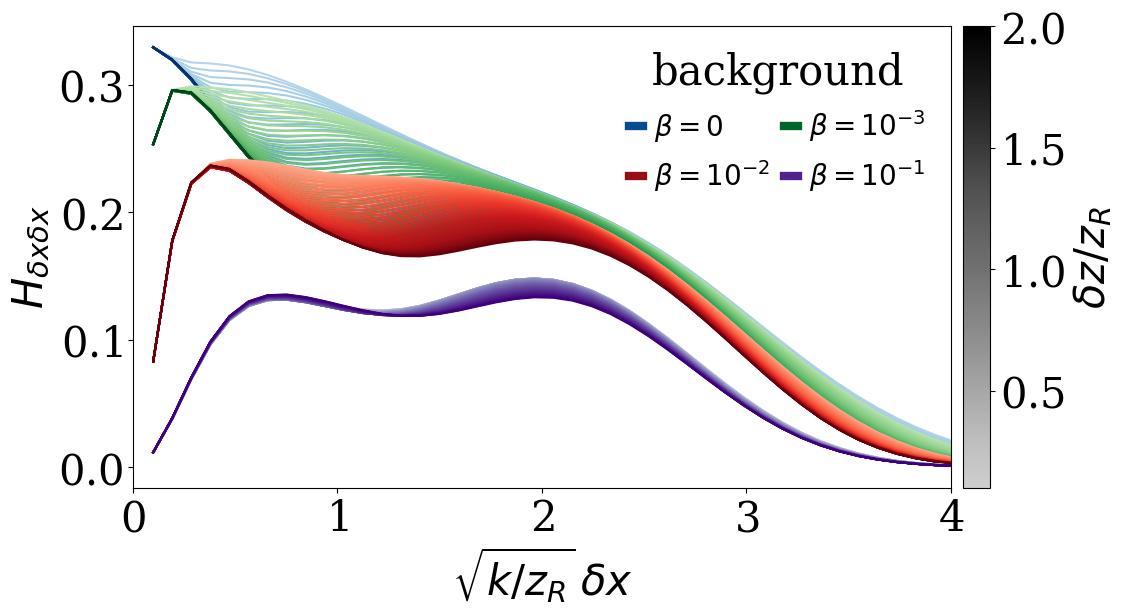

In [4]:
# Total over all channels, vs delta x. Family = beta; light->dark = delta z.
plot_fi_comparison_labeled(
    [np.sum(fi, axis=2)[:, :, DX, DX] for fi in fis],
    x_range,
    p_range,
    labels,
    cmaps=cmaps,
    xlabel=r"$\sqrt{k/z_R}\,\delta x$",
    ylabel=r"$H_{\delta x \delta x}$",
    gradient_label=r"$\delta z / z_R$",
    xlim=(0, 4),
    legend_title="background",
)
plt.savefig(f"width_fi_noise.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

## Width — Cramér–Rao bound $H^{-1}_{\delta x \delta x}$

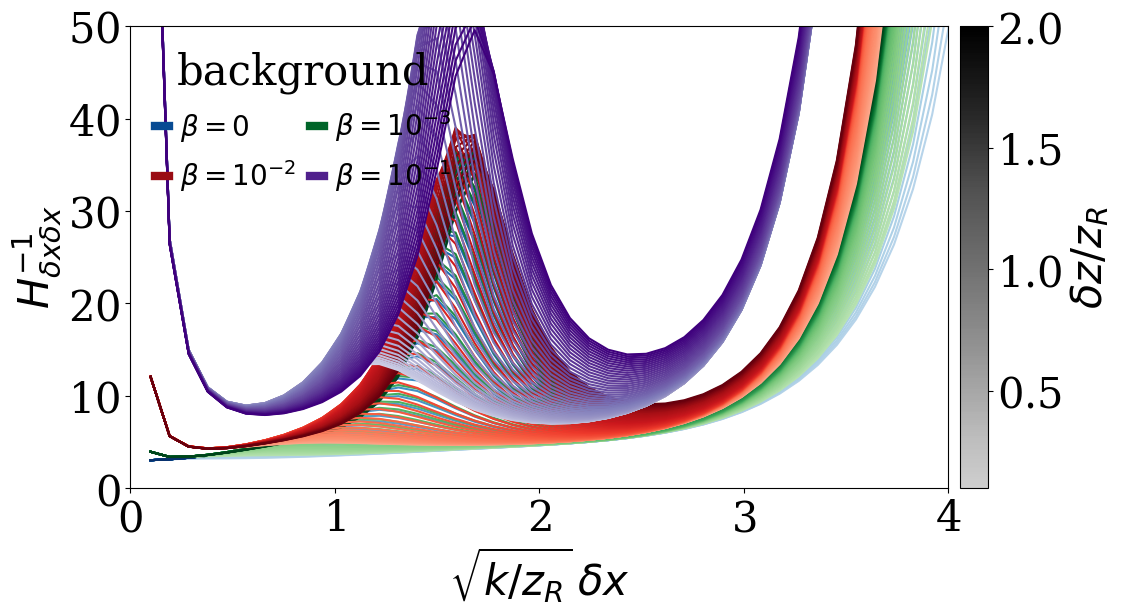

In [5]:
plot_fi_comparison_labeled(
    [fi_inv[:, :, DX, DX] for fi_inv in fis_inv],
    x_range,
    p_range,
    labels,
    cmaps=cmaps,
    xlabel=r"$\sqrt{k/z_R}\,\delta x$",
    ylabel=r"$H^{-1}_{\delta x \delta x}$",
    gradient_label=r"$\delta z / z_R$",
    xlim=(0, 4),
    ylim=(0, 50),
    legend_title="background",
)
plt.savefig(f"width_crb_noise.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

## Depth — Fisher information $H_{\delta z \delta z}$

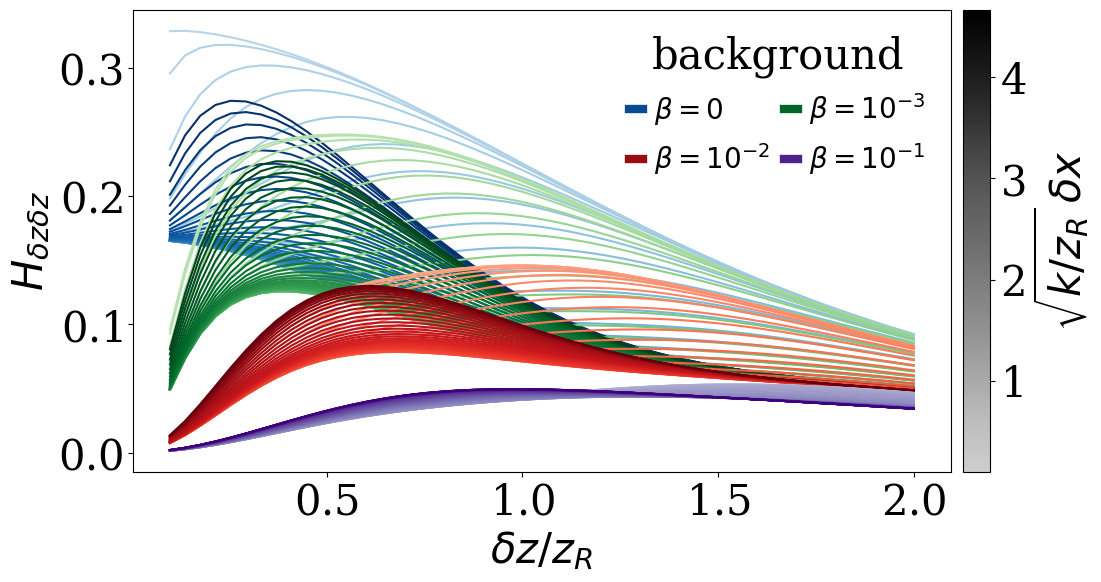

In [6]:
# Transpose so array axis 1 (delta z) becomes the horizontal axis and axis 0
# (delta x) becomes the gradient. Family = beta; light->dark = delta x.
plot_fi_comparison_labeled(
    [np.transpose(np.sum(fi, axis=2)[:, :, DZ, DZ]) for fi in fis],
    p_range,
    x_range,
    labels,
    cmaps=cmaps,
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R}\,\delta x$",
    legend_title="background",
)
plt.savefig(f"depth_fi_noise.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

## Depth — Cramér–Rao bound $H^{-1}_{\delta z \delta z}$ (headline)

The depth bound blows up as `β` grows: the floor erodes the faint depth-bearing modes first, so depth precision degrades before width.

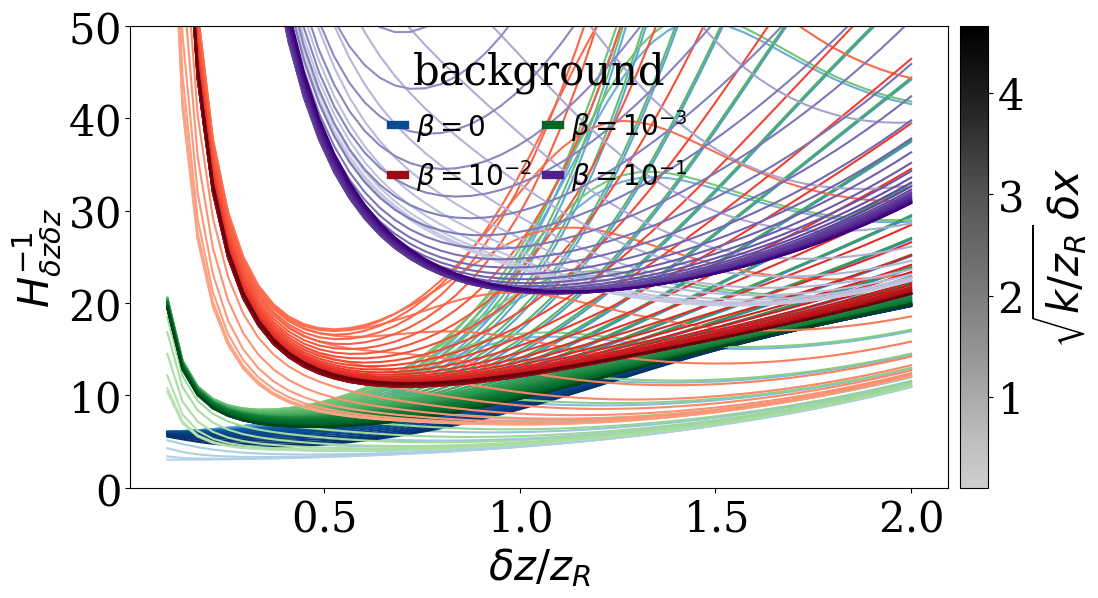

In [7]:
plot_fi_comparison_labeled(
    [np.transpose(fi_inv[:, :, DZ, DZ]) for fi_inv in fis_inv],
    p_range,
    x_range,
    labels,
    cmaps=cmaps,
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H^{-1}_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R}\,\delta x$",
    ylim=(0, 50),
    legend_title="background",
)
plt.savefig(f"depth_crb_noise.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

## Mechanism — why depth degrades first

Modes are written `(x-order, y-order)`; the sources separate along **x** (parameter `δx`, width) and the central source is displaced along **z** (parameter `δz`, depth/defocus). Per channel the Fisher information is $(\partial_\theta P)^2 / (P+\beta)$.

**Parity split (β = 0):**
- `(1,0)` is odd in x → it is populated by the transverse separation only (the SPADE mode): pure **width**, zero depth.
- `(0,2)` is even in y and flat in x, and there is no y-displacement, so it responds only to defocus: pure **depth**, zero width.
- `(2,0)` is even in x → defocus *and* the separation populate it; its large separation-driven population inflates its denominator `P`, **diluting** its depth FI (only ~6% of depth).
- `(0,0)` is the bright fundamental: defocus dims/spreads it (depth ~19%), but it is first-order-blind to a symmetric ±x split (≈0 width).

**Why the floor bites depth first:** depth's dominant carrier `(0,2)` is the faintest channel ($P\approx0.03$), whereas width's dominant carrier `(1,0)` is about twice as bright ($P\approx0.06$). The floor swamps `(0,2)` at roughly half the `β` that hurts `(1,0)`. Depth keeps a noise-robust share in the bright `(0,0)` so it never vanishes — but its information is weighted toward fainter modes, so the depth CRB rises faster than width ($\times3.2$ vs $\times2.4$ over the sweep, ~4$\times$ faster at onset).

The plot below isolates the `(2,0)+(0,2)` depth FI (~40% of the depth total) — the faint high-order information the floor erodes first.

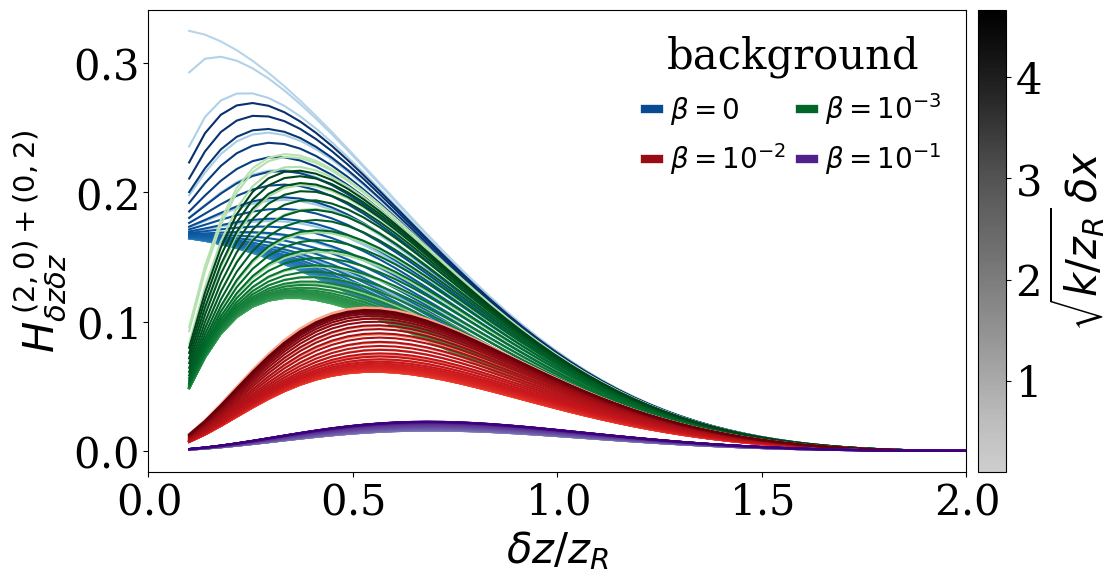

In [8]:
faint_depth_fi = [
    np.transpose(fi[:, :, DEPTH_MODE_CHANNELS, DZ, DZ].sum(axis=2)) for fi in fis
]
plot_fi_comparison_labeled(
    faint_depth_fi,
    p_range,
    x_range,
    labels,
    cmaps=cmaps,
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H^{\,(2,0)+(0,2)}_{\delta z \delta z}$",
    gradient_label=r"$\sqrt{k/z_R}\,\delta x$",
    xlim=(0, 2),
    legend_title="background",
)
plt.savefig(f"depth_fi_faint_modes_noise.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

## Composite 2×2 — FI (left) / CRB (right), width (top) / depth (bottom)

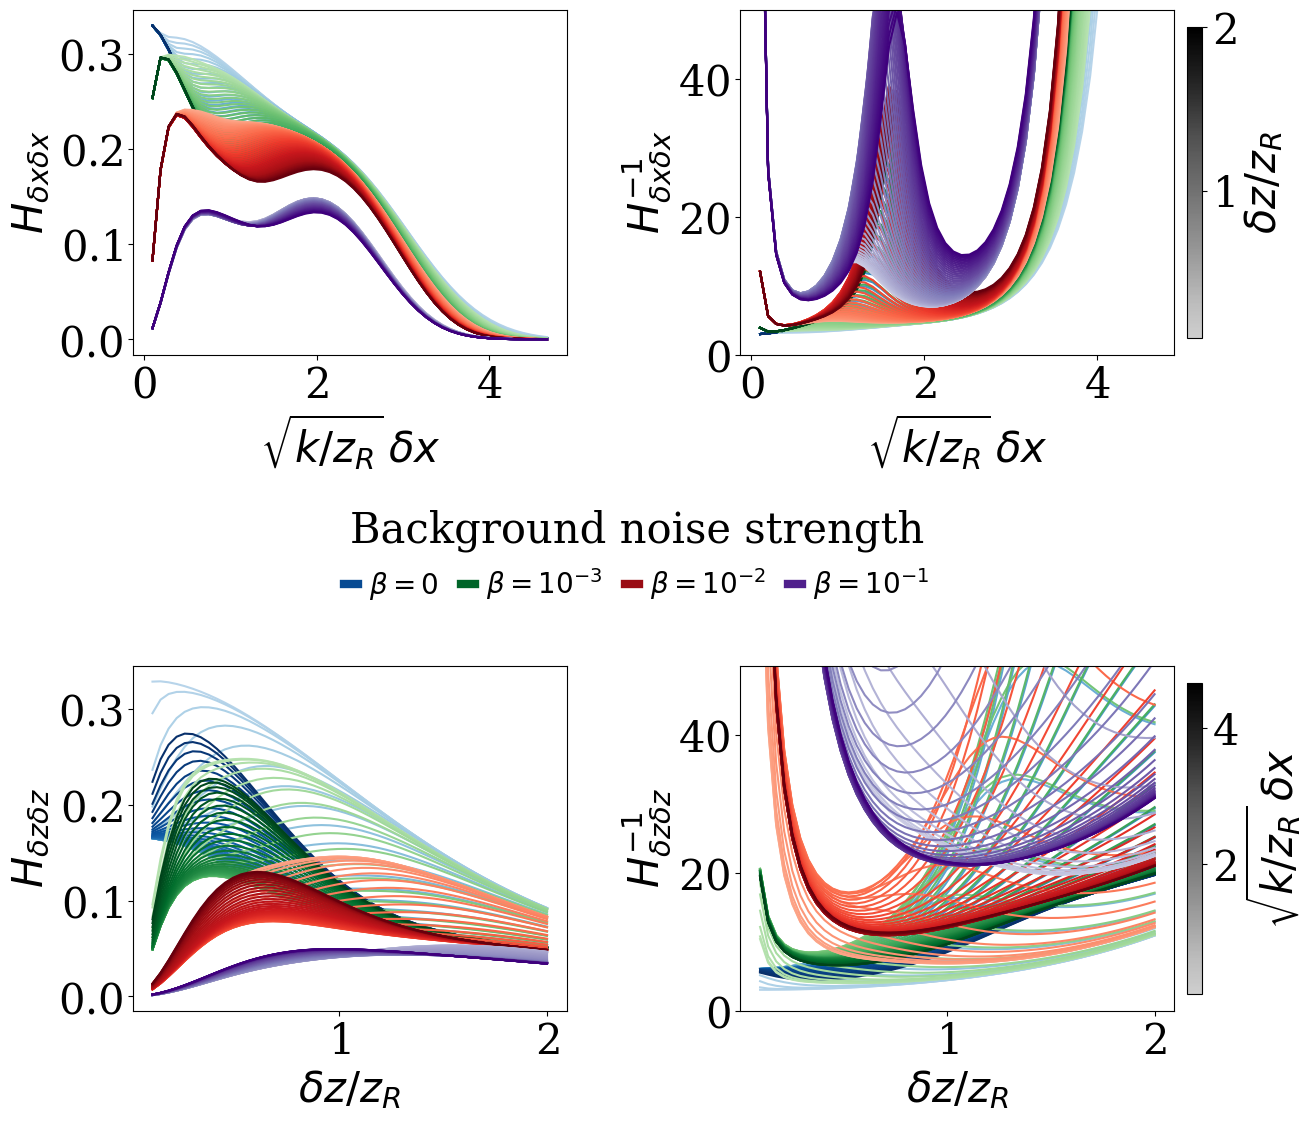

In [10]:
fig = plt.figure(figsize=(16, 13))
gs = fig.add_gridspec(2, 2, hspace=0.9, wspace=0.4)
axs = np.array([[fig.add_subplot(gs[r, c]) for c in range(2)] for r in range(2)])
n = len(SELECTED_BETAS)

# top row: width, x-axis delta x, gradient over delta z
sm_w = draw_fi_curves(
    axs[0, 0],
    [np.sum(fi, axis=2)[:, :, DX, DX] for fi in fis],
    x_range,
    p_range,
    n,
    cmaps=cmaps,
    xlabel=r"$\sqrt{k/z_R}\,\delta x$",
    ylabel=r"$H_{\delta x \delta x}$",
)
draw_fi_curves(
    axs[0, 1],
    [fi_inv[:, :, DX, DX] for fi_inv in fis_inv],
    x_range,
    p_range,
    n,
    cmaps=cmaps,
    xlabel=r"$\sqrt{k/z_R}\,\delta x$",
    ylabel=r"$H^{-1}_{\delta x \delta x}$",
    ylim=(0, 50),
)

# bottom row: depth, x-axis delta z, gradient over delta x
sm_d = draw_fi_curves(
    axs[1, 0],
    [np.transpose(np.sum(fi, axis=2)[:, :, DZ, DZ]) for fi in fis],
    p_range,
    x_range,
    n,
    cmaps=cmaps,
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H_{\delta z \delta z}$",
)
draw_fi_curves(
    axs[1, 1],
    [np.transpose(fi_inv[:, :, DZ, DZ]) for fi_inv in fis_inv],
    p_range,
    x_range,
    n,
    cmaps=cmaps,
    xlabel=r"$\delta z / z_R$",
    ylabel=r"$H^{-1}_{\delta z \delta z}$",
    ylim=(0, 50),
)

fig.colorbar(
    sm_w,
    ax=axs[0, :],
    location="right",
    shrink=0.9,
    pad=0.01,
    label=r"$\delta z / z_R$",
)
fig.colorbar(
    sm_d,
    ax=axs[1, :],
    location="right",
    shrink=0.9,
    pad=0.01,
    label=r"$\sqrt{k/z_R}\,\delta x$",
)

fig.legend(
    handles=fi_legend_handles_labeled(labels, cmaps=cmaps, legend_ncol=n),
    title="Background noise strength",
    frameon=False,
    loc="center",
    bbox_to_anchor=(0.44, 0.46),
    ncol=n,
    handlelength=0.5,
    handletextpad=0.4,
    columnspacing=0.8,
)

fig.savefig(f"combined_fi_crb_noise.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()